In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

daily_data = pd.read_csv('KO_weekly_return_detailed.csv')
weekly_labels = pd.read_csv('KO_weekly_return_volatility.csv')

ANALYZE_YEARS = [2025]  # ← CHANGE THIS to [2021], [2022], [2021, 2022], etc.
ANALYSIS_NAME = "2025"  # ← Name for the output files

weekly_labels_filtered = weekly_labels[weekly_labels['Year'].isin(ANALYZE_YEARS)].reset_index(drop=True)
daily_data_filtered = daily_data[daily_data['Year'].isin(ANALYZE_YEARS)].reset_index(drop=True)

initial_balance = 100
current_balance = initial_balance
position = None  # None = cash, 'invested' = have position

results = []

print(f"\nStarting simulation with ${initial_balance:.2f}")
print(f"Total weeks to process: {len(weekly_labels_filtered)}")

# Loop through all weeks
for week_idx in range(len(weekly_labels_filtered)):
    current_week = weekly_labels_filtered.iloc[week_idx]
    year = current_week['Year']
    week_num = current_week['Week_Number']

    # data for current week
    week_data = daily_data_filtered[
        (daily_data_filtered['Year'] == year) &
        (daily_data_filtered['Week_Number'] == week_num)
        ].copy()

    if len(week_data) == 0:
        continue

    last_trading_day = week_data.iloc[-1]['Weekday']

    week_start_balance = current_balance

    if position == 'invested':
        for idx, row in week_data.iterrows():
            if pd.notna(row['Return']):
                current_balance = current_balance * (1 + row['Return'] / 100)

    # If this is not the last week
    if week_idx < len(weekly_labels_filtered) - 1:
        next_week = weekly_labels_filtered.iloc[week_idx + 1]
        next_week_decision = next_week['decision']

        if next_week_decision == 'YES':  # Green
            if position is None:  # No position - BUY
                position = 'invested'
            else:  # Already invested - HOLD
                pass
        else:  # Red
            if position == 'invested':  # Have position - SELL
                position = None
            else:  # No position - STAY in cash
                pass

    results.append({
        'Year': year,
        'Week': week_num,
        'Last_Day': last_trading_day,
        'End_Balance': current_balance
    })

results_df = pd.DataFrame(results)

print(f"\nInitial Balance: ${initial_balance:.2f}")
print(f"Final Balance: ${current_balance:.2f}")
print(
    f"Total Return: ${current_balance - initial_balance:.2f} ({((current_balance / initial_balance - 1) * 100):.2f}%)")

# weekly balances
weekly_balances = results_df['End_Balance'].values



Starting simulation with $100.00
Total weeks to process: 53

Initial Balance: $100.00
Final Balance: $112.68
Total Return: $12.68 (12.68%)


1. Average and Volatility of Weekly Balances

In [20]:
average_balance = weekly_balances.mean()
volatility_balance = weekly_balances.std()

print(f"Average weekly balance: ${average_balance:.2f}")
print(f"Volatility (std dev) of weekly balances: ${volatility_balance:.2f}")

Average weekly balance: $110.29
Volatility (std dev) of weekly balances: $3.64


2. plot the "growth" of your account. Week numbers on x, account balance on y

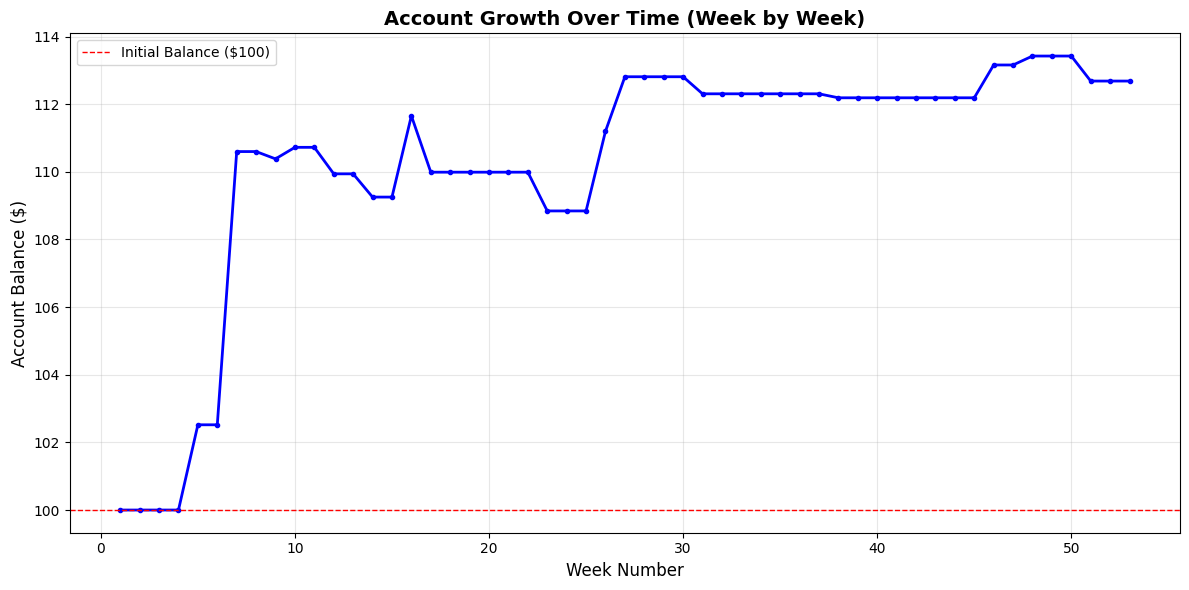

In [21]:
plt.figure(figsize=(12, 6))
plt.plot(range(1, len(weekly_balances) + 1), weekly_balances,
         linewidth=2, color='blue', marker='o', markersize=3)
plt.axhline(y=100, color='red', linestyle='--', linewidth=1, label='Initial Balance ($100)')
plt.xlabel('Week Number', fontsize=12)
plt.ylabel('Account Balance ($)', fontsize=12)
plt.title('Account Growth Over Time (Week by Week)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

3. what (and when) was the min & max of the account?

In [22]:
min_balance = weekly_balances.min()
max_balance = weekly_balances.max()

min_idx = weekly_balances.argmin()
max_idx = weekly_balances.argmax()

min_week = results_df.iloc[min_idx]
max_week = results_df.iloc[max_idx]

print(f"Minimum Balance: ${min_balance:.2f}")
print(f"  When: Week {min_week['Week']}/{min_week['Year']} ({min_week['Last_Day']})")

print(f"\nMaximum Balance: ${max_balance:.2f}")
print(f"  When: Week {max_week['Week']}/{max_week['Year']} ({max_week['Last_Day']})")

Minimum Balance: $100.00
  When: Week 0/2025 (Friday)

Maximum Balance: $113.42
  When: Week 47/2025 (Friday)


4. what was the final value of the account?

In [23]:
final_balance = weekly_balances[-1]
print(f"Final account value: ${final_balance:.2f}")

Final account value: $112.68


5. what was the maximum duration (in weeks) that your account was growing and what was the maximum duration (in weeks) that your account was decreasing in value?

In [24]:
# Calculate week-to-week changes
balance_changes = np.diff(weekly_balances)

max_growth_streak = 0
max_decline_streak = 0
current_growth_streak = 0
current_decline_streak = 0

for change in balance_changes:
    if change > 0:  # Growing
        current_growth_streak += 1
        current_decline_streak = 0
        max_growth_streak = max(max_growth_streak, current_growth_streak)
    elif change < 0:  # Declining
        current_decline_streak += 1
        current_growth_streak = 0
        max_decline_streak = max(max_decline_streak, current_decline_streak)
    else:  # No change
        current_growth_streak = 0
        current_decline_streak = 0

print(f"Maximum growth streak: {max_growth_streak} consecutive weeks")
print(f"Maximum decline streak: {max_decline_streak} consecutive weeks")

csv_filename = f'trading_results_{ANALYSIS_NAME}.csv'
results_df.to_csv(csv_filename, index=False)
print(f"\n✓ Results saved to: {csv_filename}")

Maximum growth streak: 2 consecutive weeks
Maximum decline streak: 1 consecutive weeks

✓ Results saved to: trading_results_2025.csv
